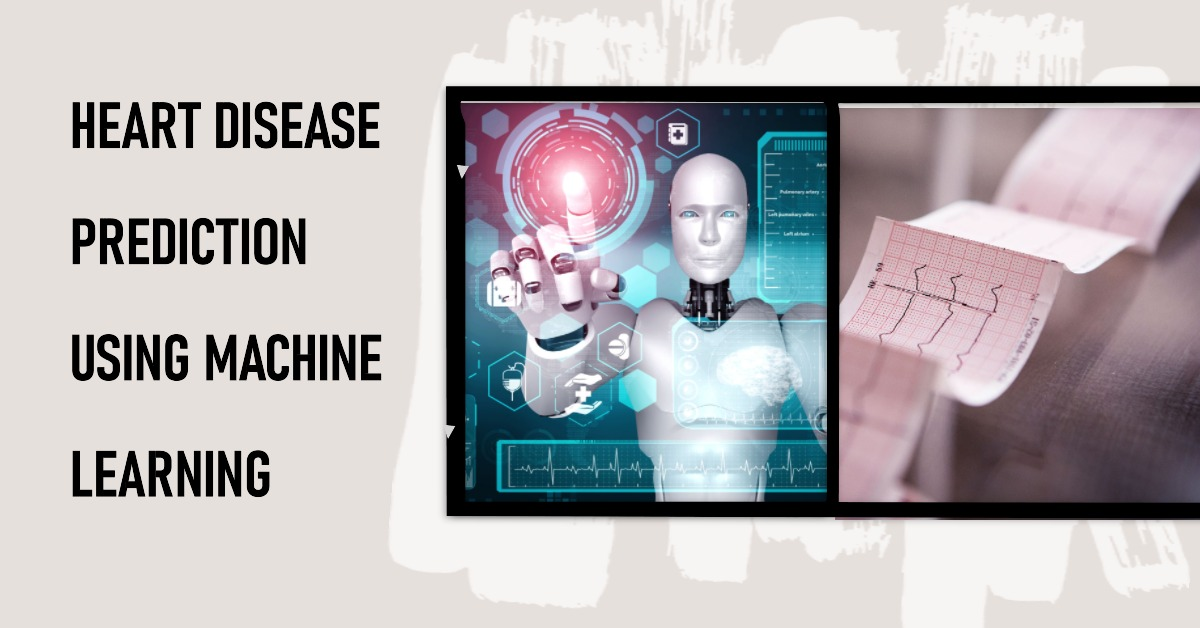

# **#ABSTRACT**
Heart disease is one of the major causes of death in the world, and early detection is essential for efficient treatment and the reduction of its negative effects. We seek to construct a heart disease prediction model using machine learning methods in this research. Machine learning algorithms have demonstrated considerable potential for effectively predicting heart disease. To train and test our model, we use a patient data collection that is openly accessible. We evaluate the performance of various machine learning techniques, such as support vector machines, decision trees, and random forests, and choose the model that performs the best. Our findings demonstrate that the created model is highly accurate and useful for predicting cardiac disease. This project will have significant effects on the healthcare industry and can assist healthcare professionals in serving better care to the patients with heart disease.

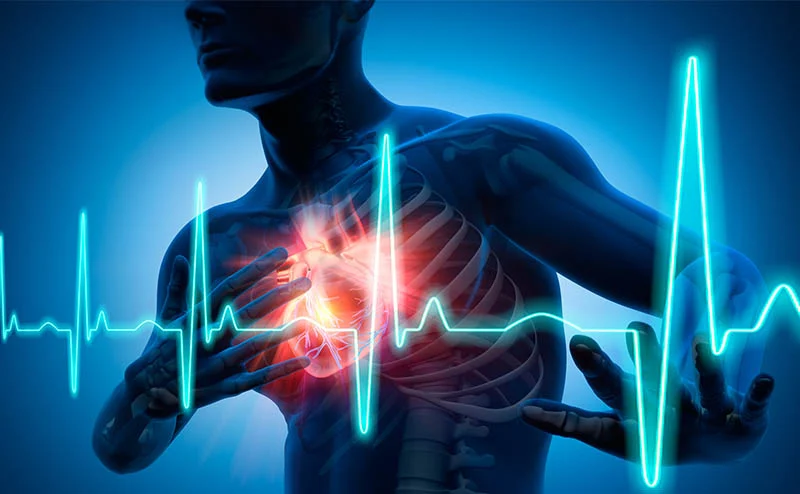

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import svm, neighbors
from sklearn.ensemble import VotingClassifier
%matplotlib inline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')
from sklearn.ensemble import RandomForestClassifier
import io
import random as rnd
import os


In [2]:
df = pd.read_csv('heart.csv')


In [3]:
df.head()


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [4]:
df.tail()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
1020,59,1,1,140,221,0,1,164,1,0.0,2,0,2,1
1021,60,1,0,125,258,0,0,141,1,2.8,1,1,3,0
1022,47,1,0,110,275,0,0,118,1,1.0,1,1,2,0
1023,50,0,0,110,254,0,0,159,0,0.0,2,0,2,1
1024,54,1,0,120,188,0,1,113,0,1.4,1,1,3,0


**VISUALLY CHECKING IF OUR DATA CONTAINS ANY MISSING VALUES**`

False

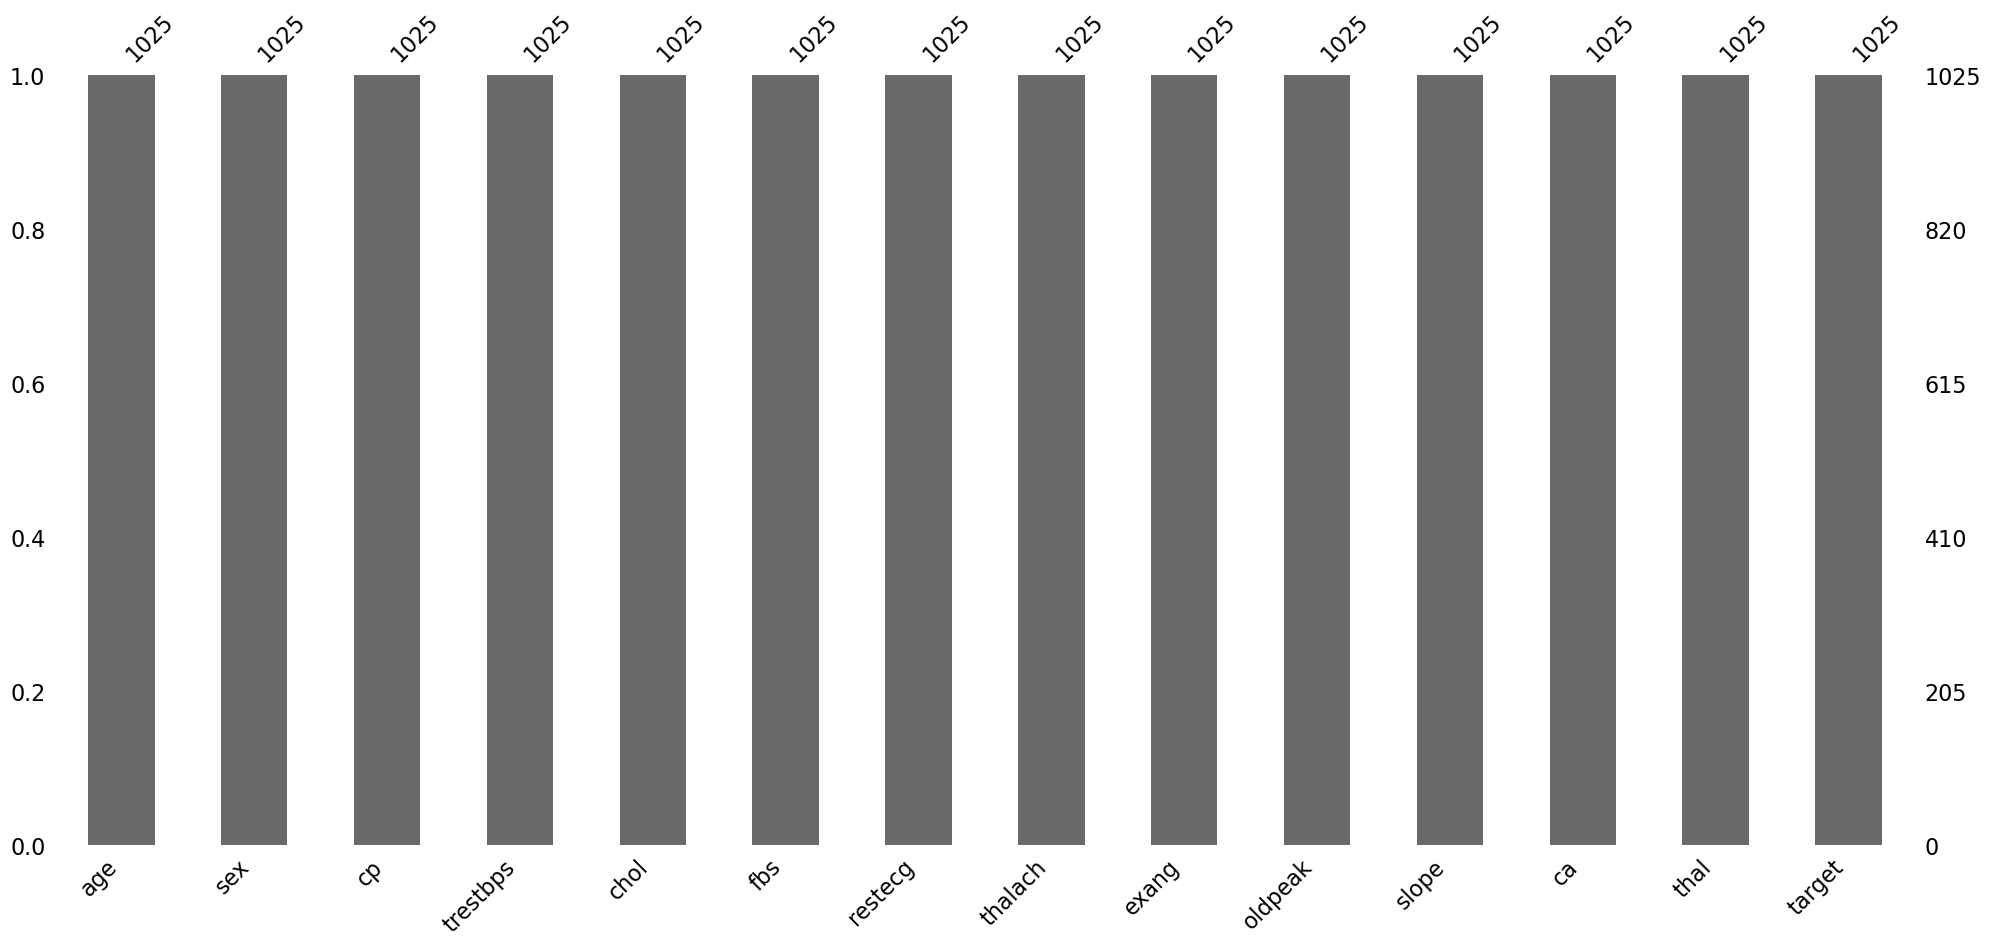

In [5]:
import missingno as msn
msn.bar(df)
# Checking for missing values.
df.isnull().values.any()

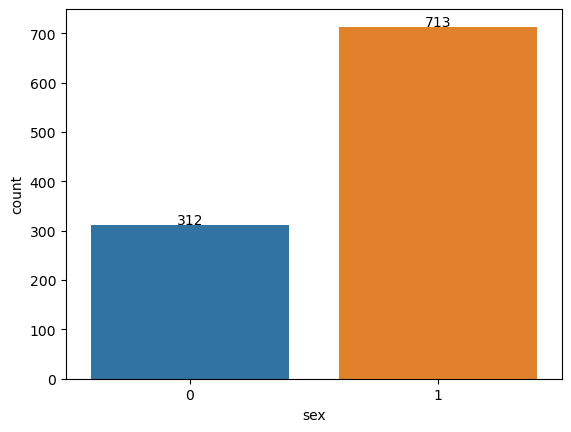

In [6]:
ax = sns.countplot(x="sex", data=df)

# Add count labels to bars
for p in ax.patches:
    height = p.get_height()
    ax.text(p.get_x() + p.get_width()/2, height+0.3,'{:.0f}'.format(height), ha="center")
    

In [7]:
import plotly.express as px


In [8]:
Hdislabel = ['Have heart disease','Do not have heart disease']
val_counts = [508,409] 
fig = px.pie(values=val_counts,names=Hdislabel,
             color=Hdislabel,
             color_discrete_map={'Have heart disease':'red',
                                 'Do not have heart disease':'#13F306'},
             title='Heart disease count')

fig.show()

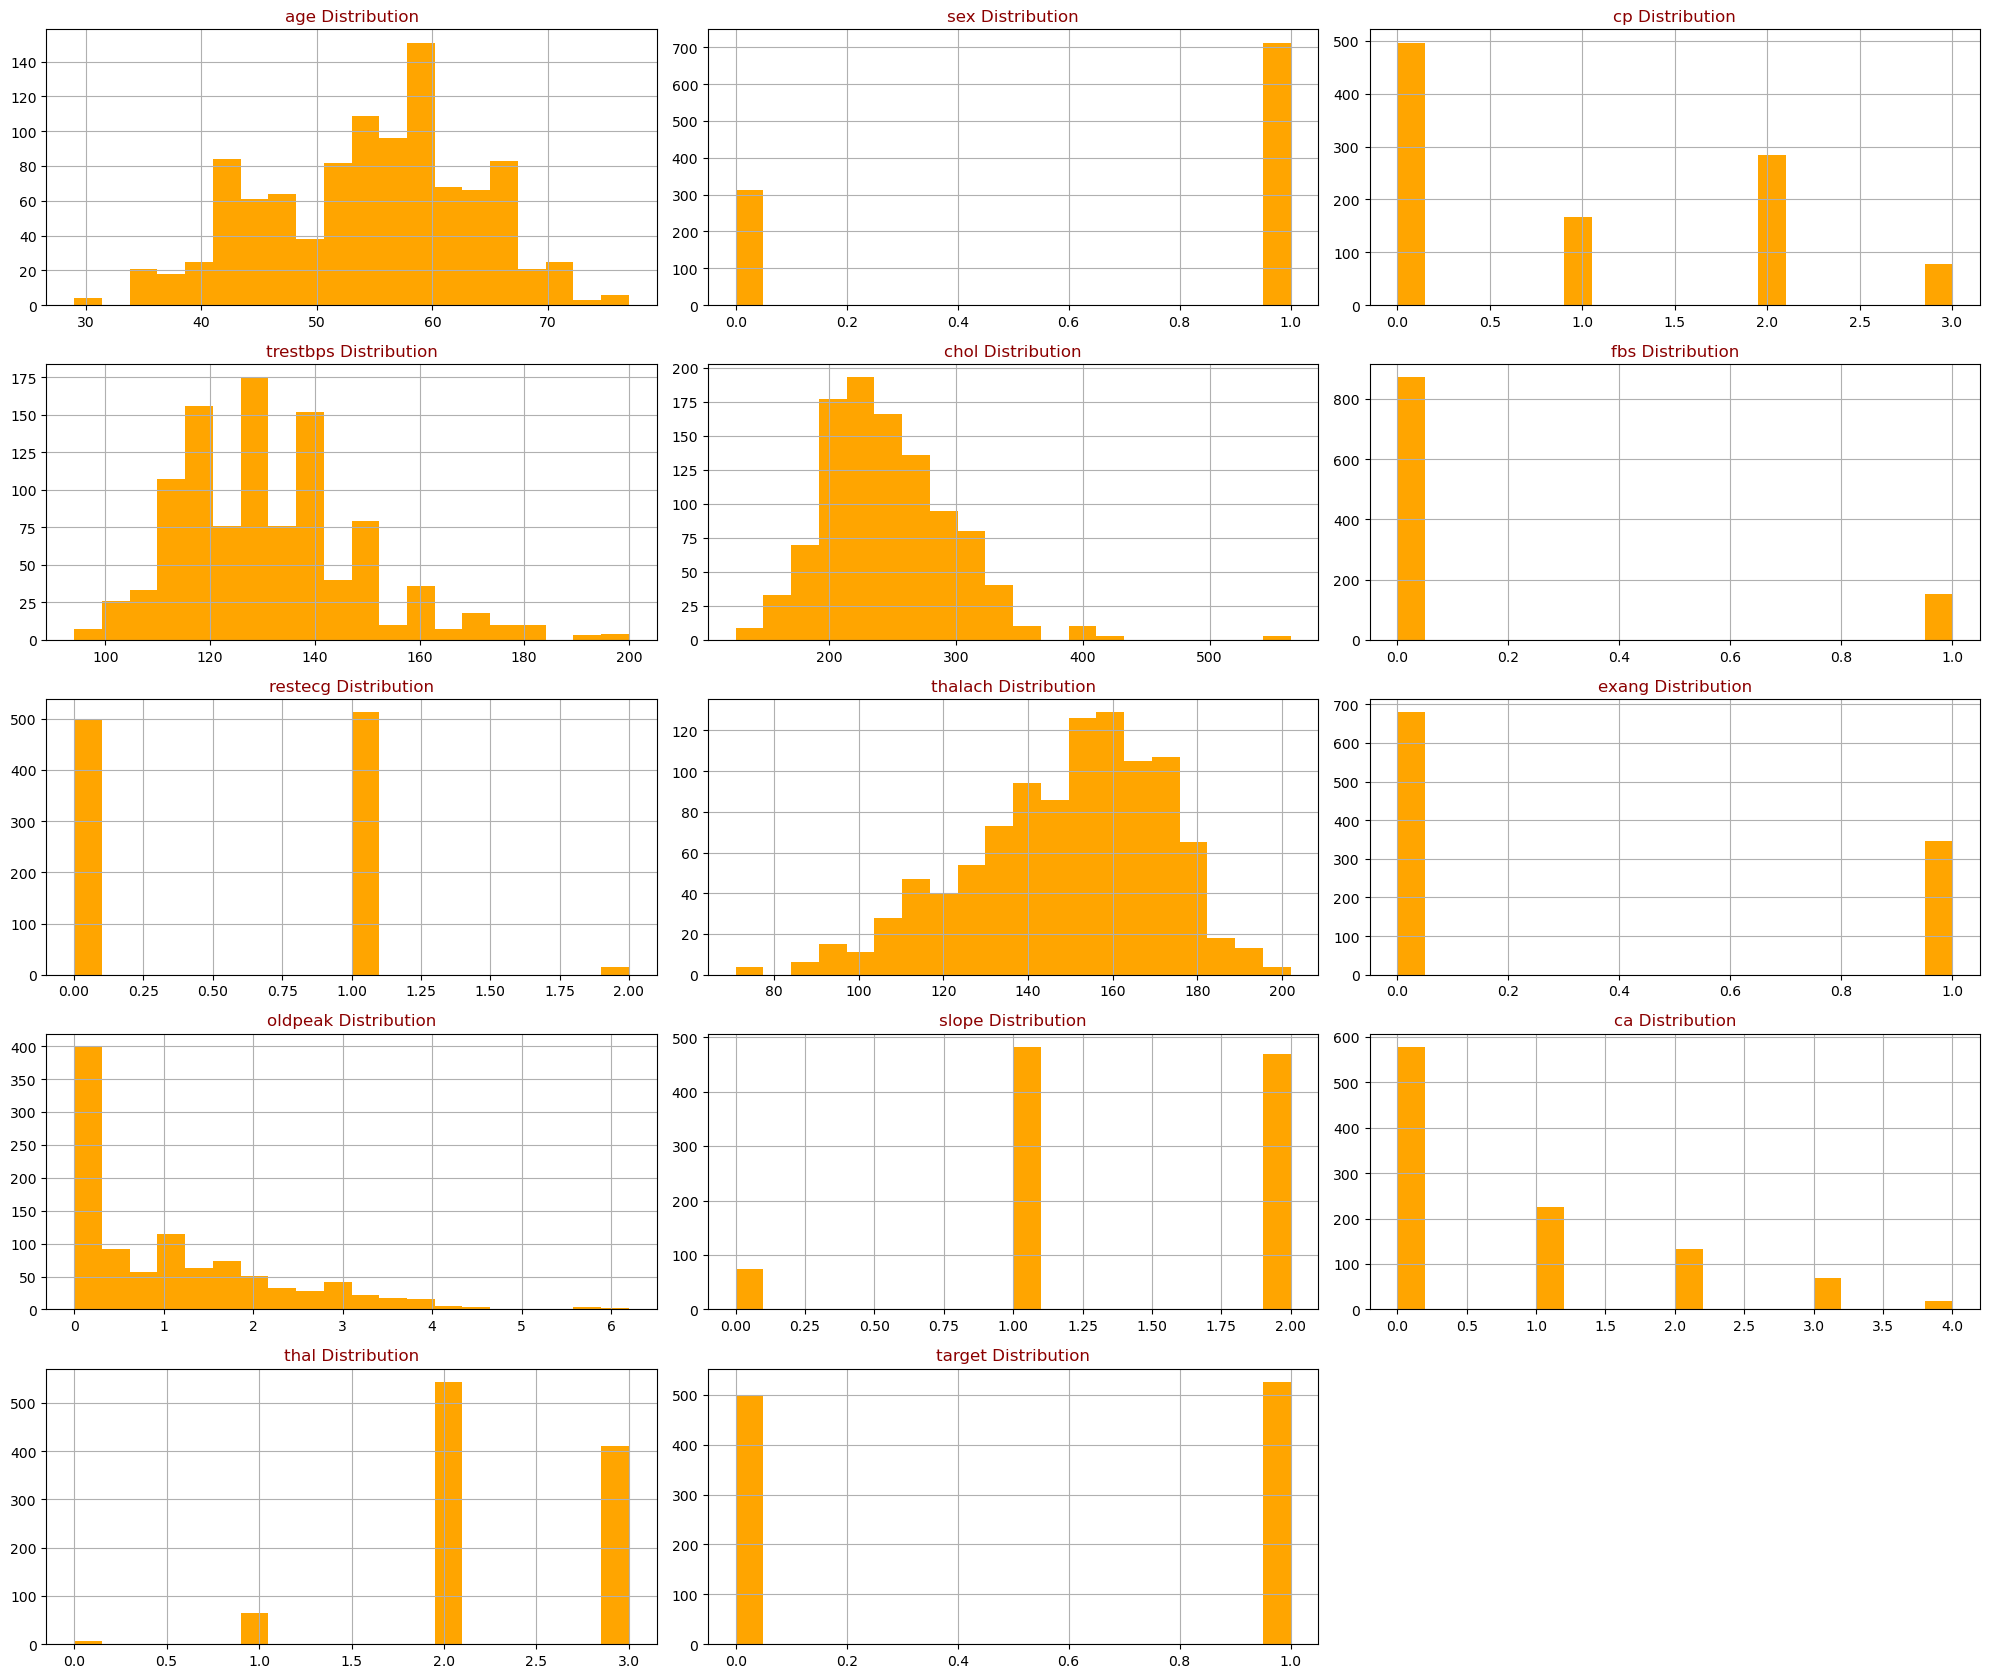

In [9]:
def draw_histograms(dataframe, features, rows, cols):
    fig=plt.figure(figsize=(20,20))
    for i, feature in enumerate(features):
        ax=fig.add_subplot(rows,cols,i+1)
        dataframe[feature].hist(bins=20,ax=ax,facecolor='ORANGE')
        ax.set_title(feature+" Distribution",color='DarkRed')
        
    fig.tight_layout()  
    plt.show()
draw_histograms(df,df.columns,6,3)

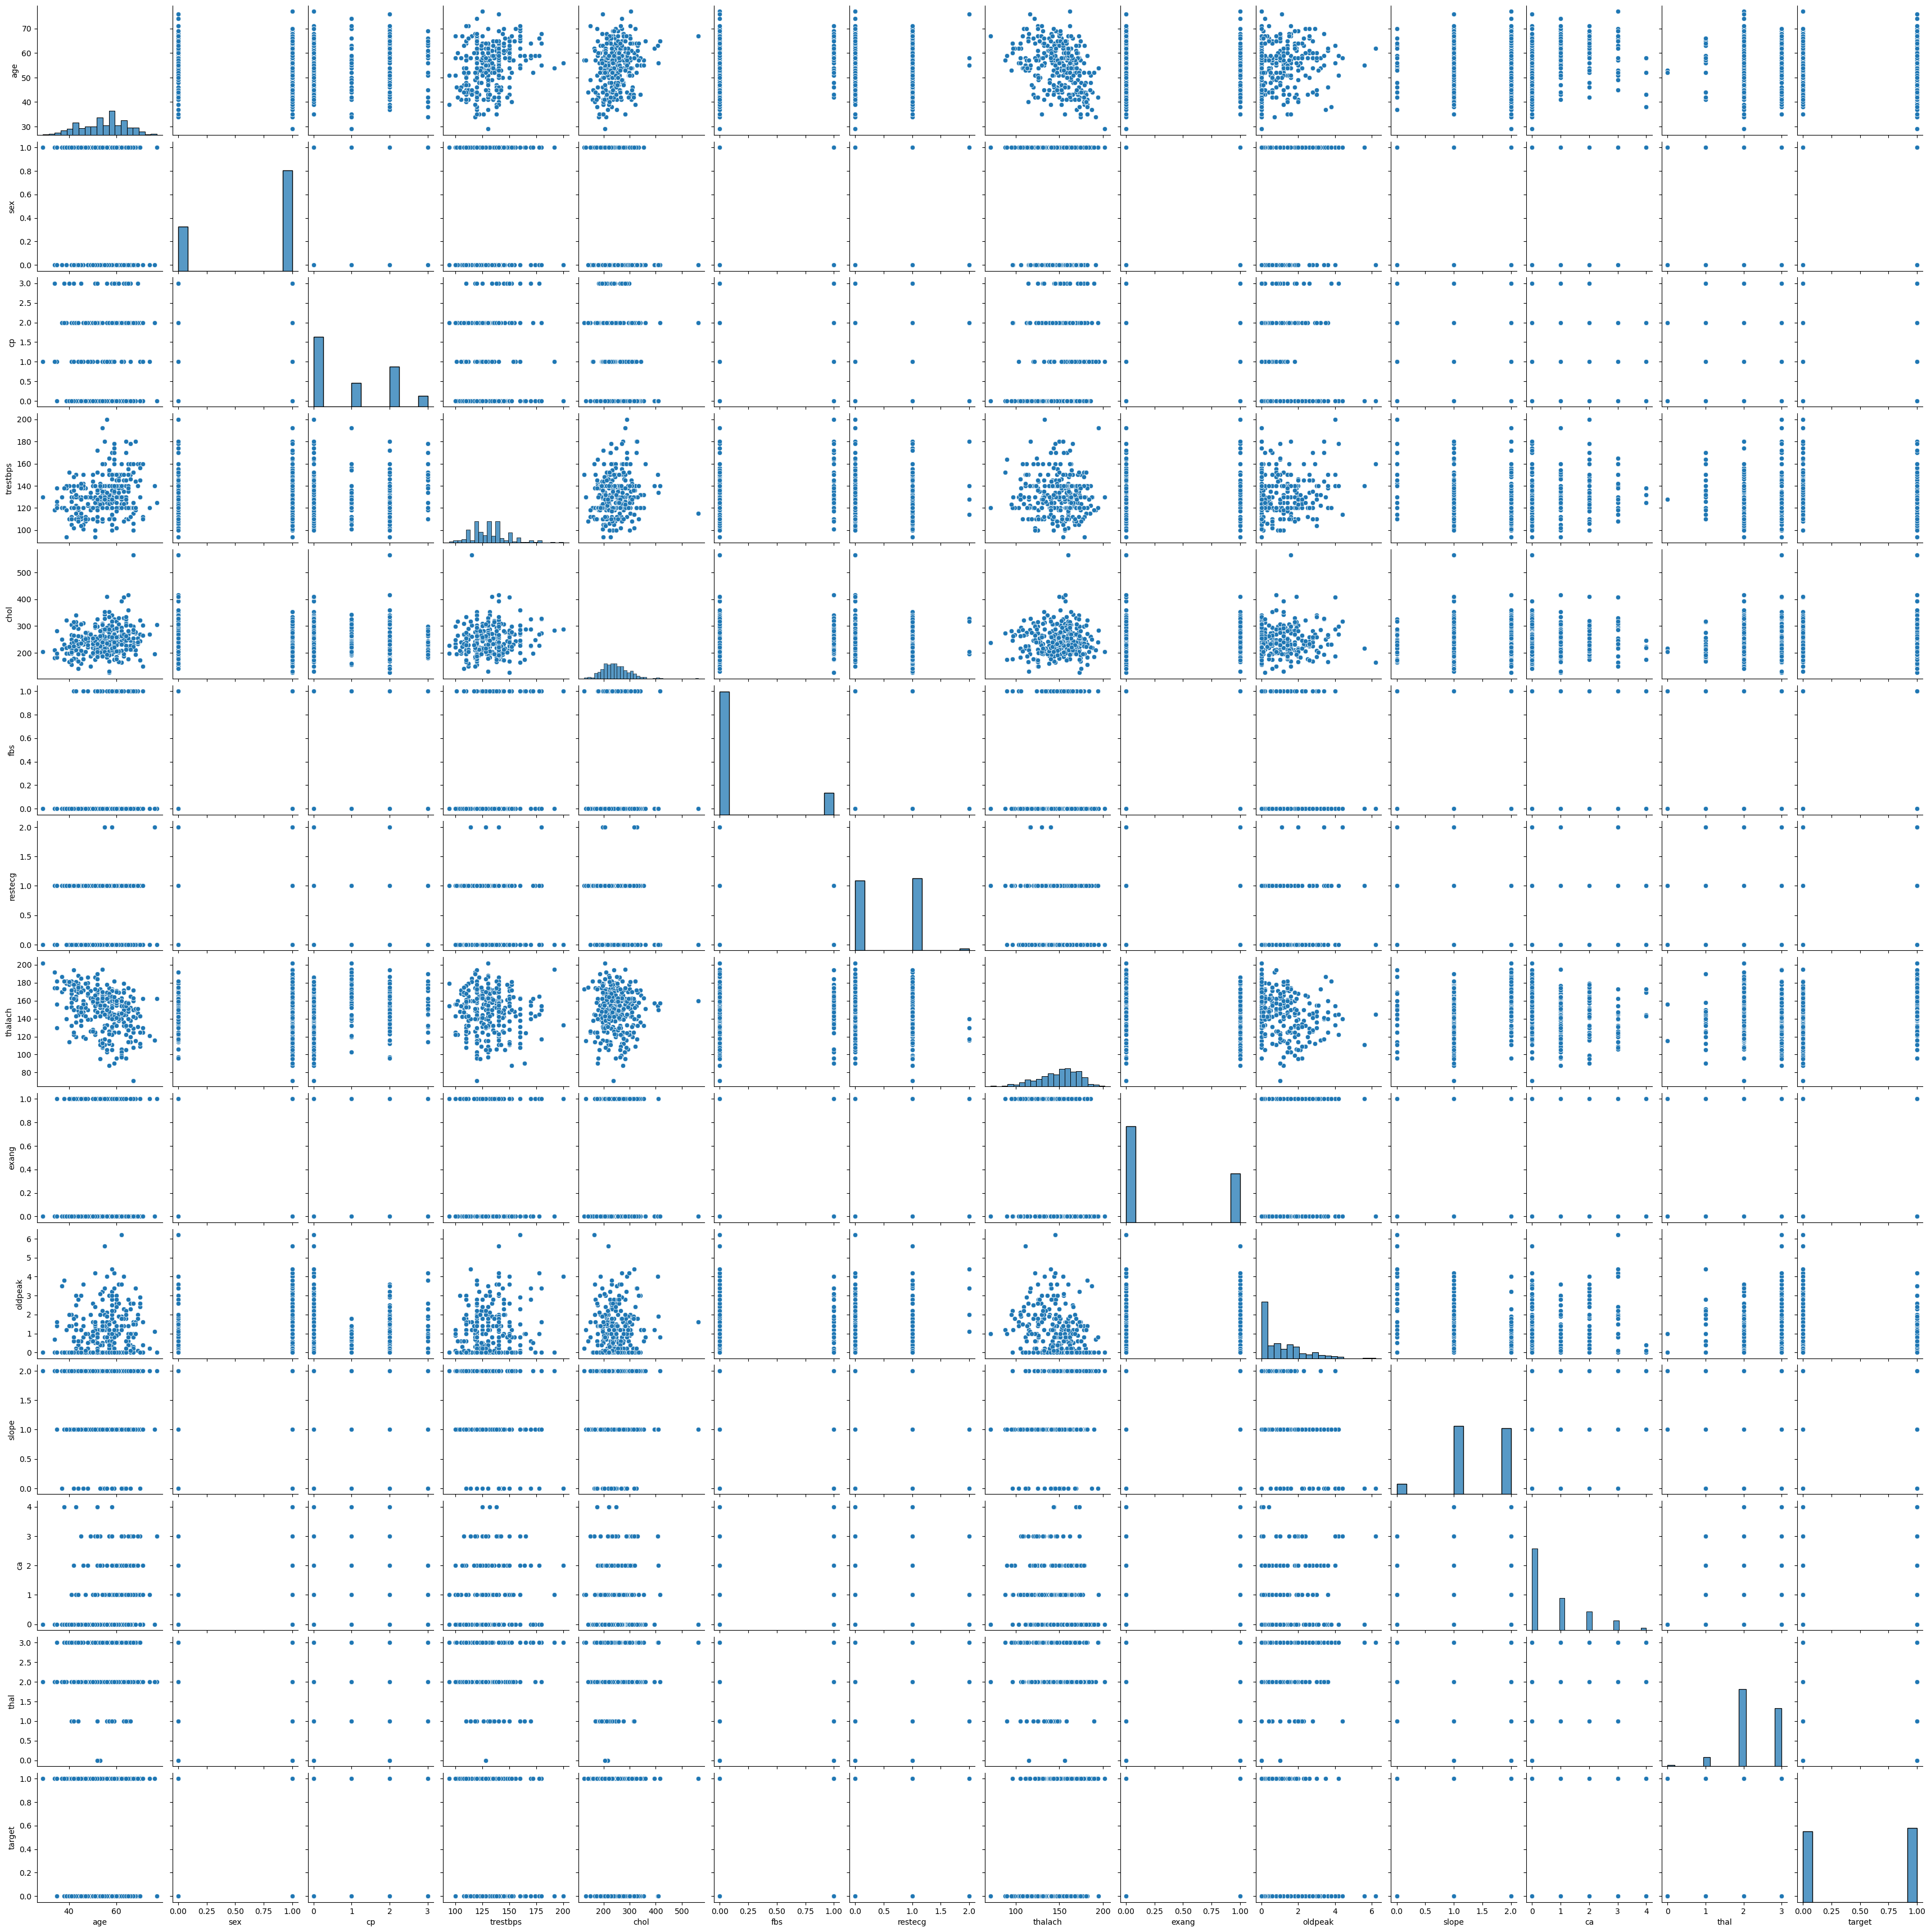

In [10]:

sns.pairplot(data=df)


In [11]:
# Checking for any correlations.
df.corr()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
age,1.000000,-0.103240,-0.071966,0.271121,0.219823,0.121243,-0.132696,-0.390227,0.088163,0.208137,-0.169105,0.271551,0.072297,-0.229324
sex,-0.103240,1.000000,-0.041119,-0.078974,-0.198258,0.027200,-0.055117,-0.049365,0.139157,0.084687,-0.026666,0.111729,0.198424,-0.279501
cp,-0.071966,-0.041119,1.000000,0.038177,-0.081641,0.079294,0.043581,0.306839,-0.401513,-0.174733,0.131633,-0.176206,-0.163341,0.434854
trestbps,0.271121,-0.078974,0.038177,1.000000,0.127977,0.181767,-0.123794,-0.039264,0.061197,0.187434,-0.120445,0.104554,0.059276,-0.138772
chol,0.219823,-0.198258,-0.081641,0.127977,1.000000,0.026917,-0.147410,-0.021772,0.067382,0.064880,-0.014248,0.074259,0.100244,-0.099966
fbs,0.121243,0.027200,0.079294,0.181767,0.026917,1.000000,-0.104051,-0.008866,0.049261,0.010859,-0.061902,0.137156,-0.042177,-0.041164
restecg,-0.132696,-0.055117,0.043581,-0.123794,-0.147410,-0.104051,1.000000,0.048411,-0.065606,-0.050114,0.086086,-0.078072,-0.020504,0.134468
thalach,-0.390227,-0.049365,0.306839,-0.039264,-0.021772,-0.008866,0.048411,1.000000,-0.380281,-0.349796,0.395308,-0.207888,-0.098068,0.422895
exang,0.088163,0.139157,-0.401513,0.061197,0.067382,0.049261,-0.065606,-0.380281,1.000000,0.310844,-0.267335,0.107849,0.197201,-0.438029
oldpeak,0.208137,0.084687,-0.174733,0.187434,0.064880,0.010859,-0.050114,-0.349796,0.310844,1.000000,-0.575189,0.221816,0.202672,-0.438441


Text(0.5, -0.23, 'Fig: Annotated values of correlation coefficient of each pair of features')

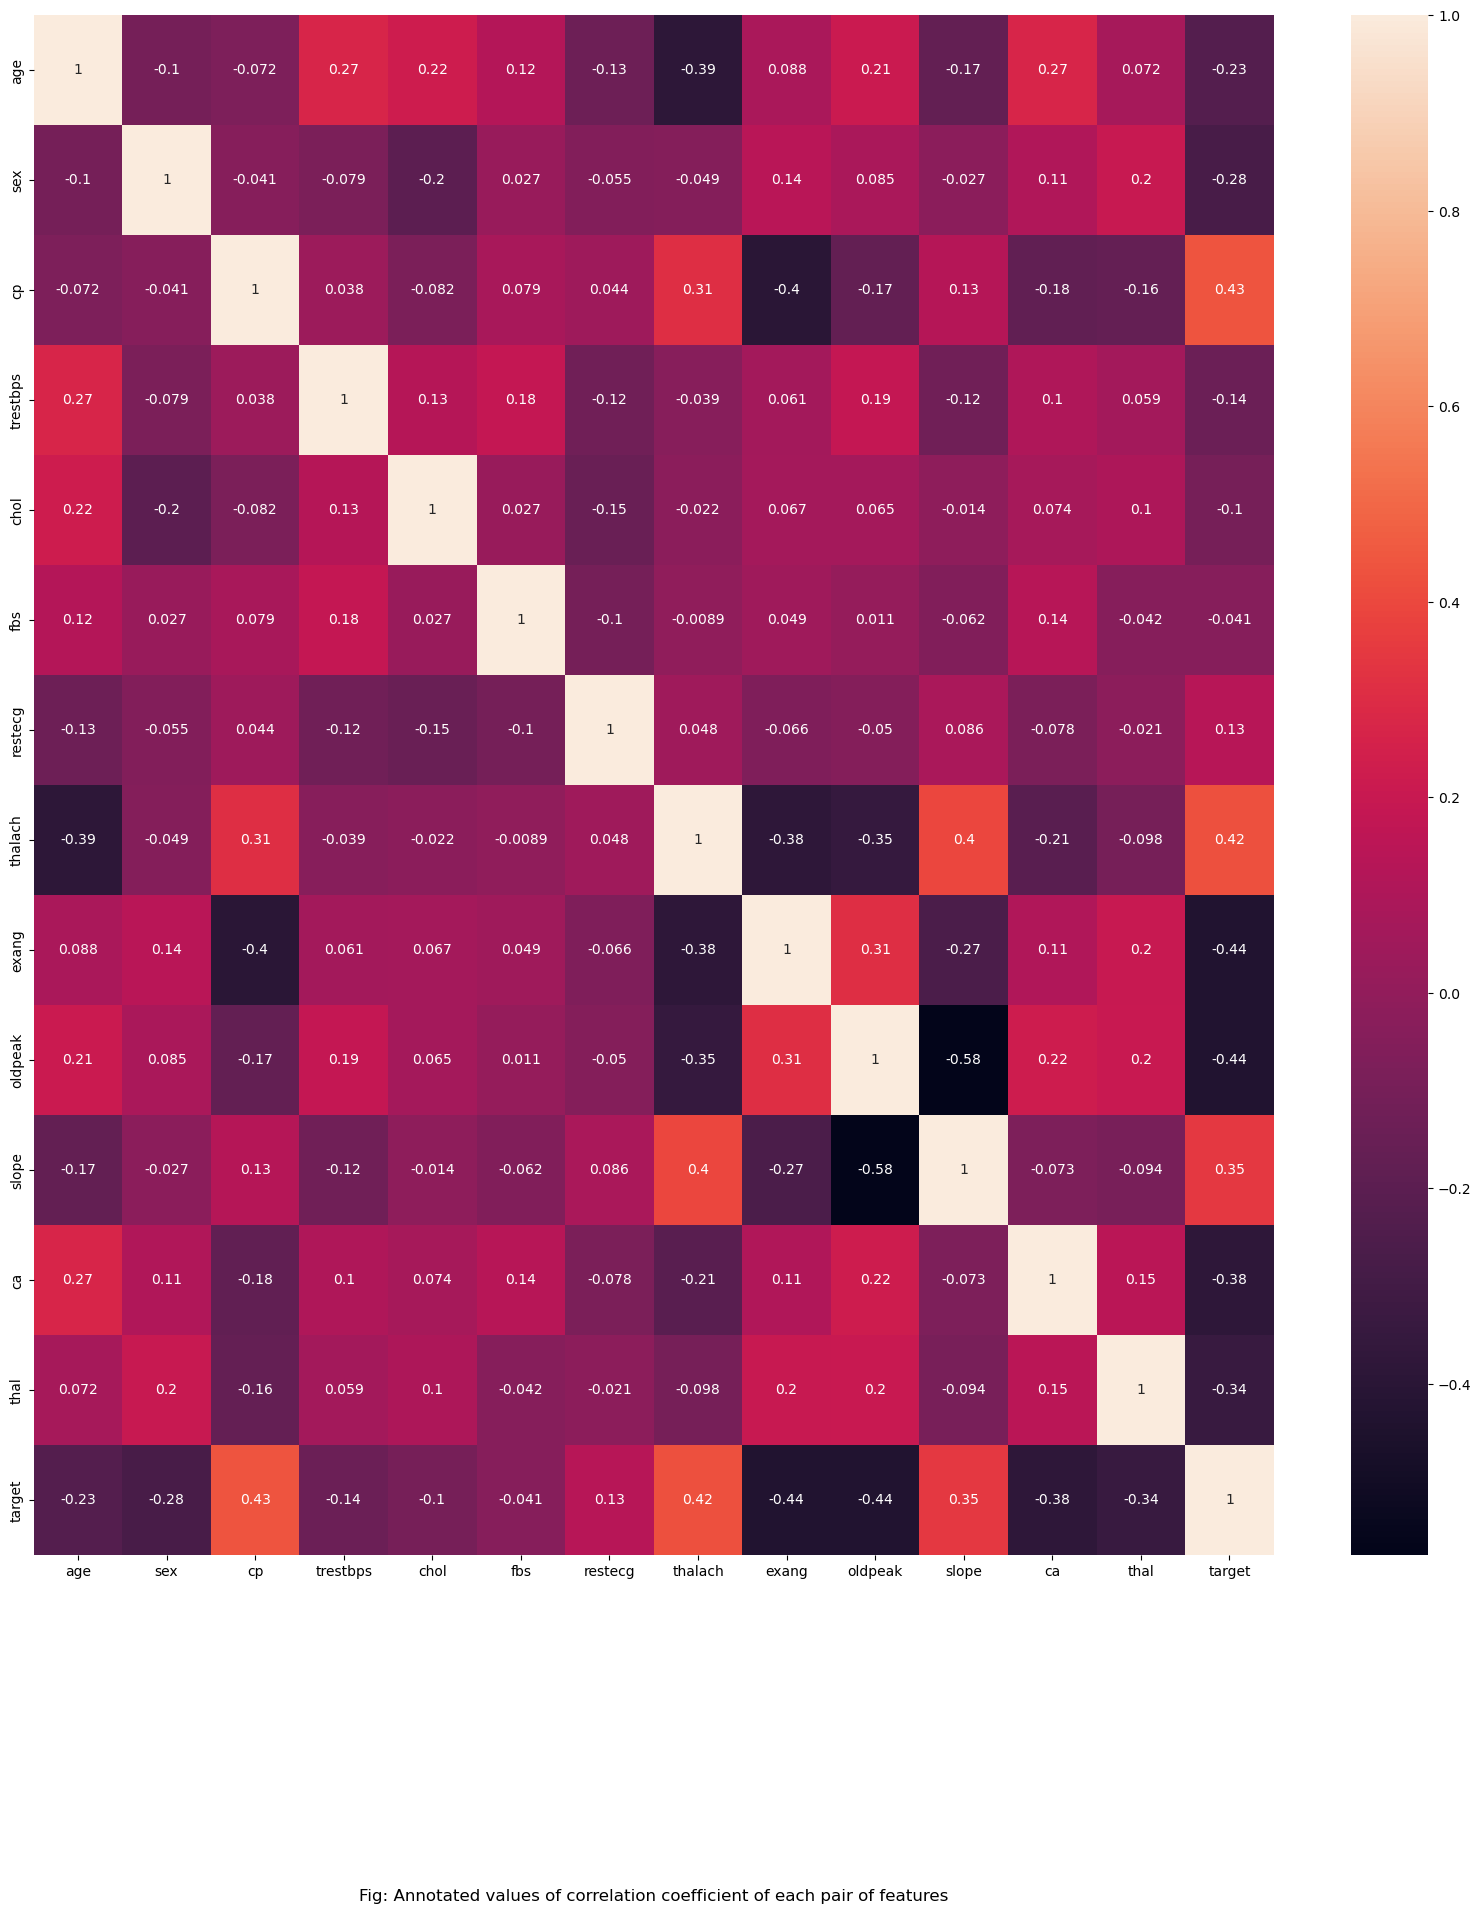

In [12]:
plt.figure(figsize = (20, 20))
sns.heatmap(df.corr(),annot=True)
plt.title('Fig: Annotated values of correlation coefficient of each pair of features', y=-0.23)

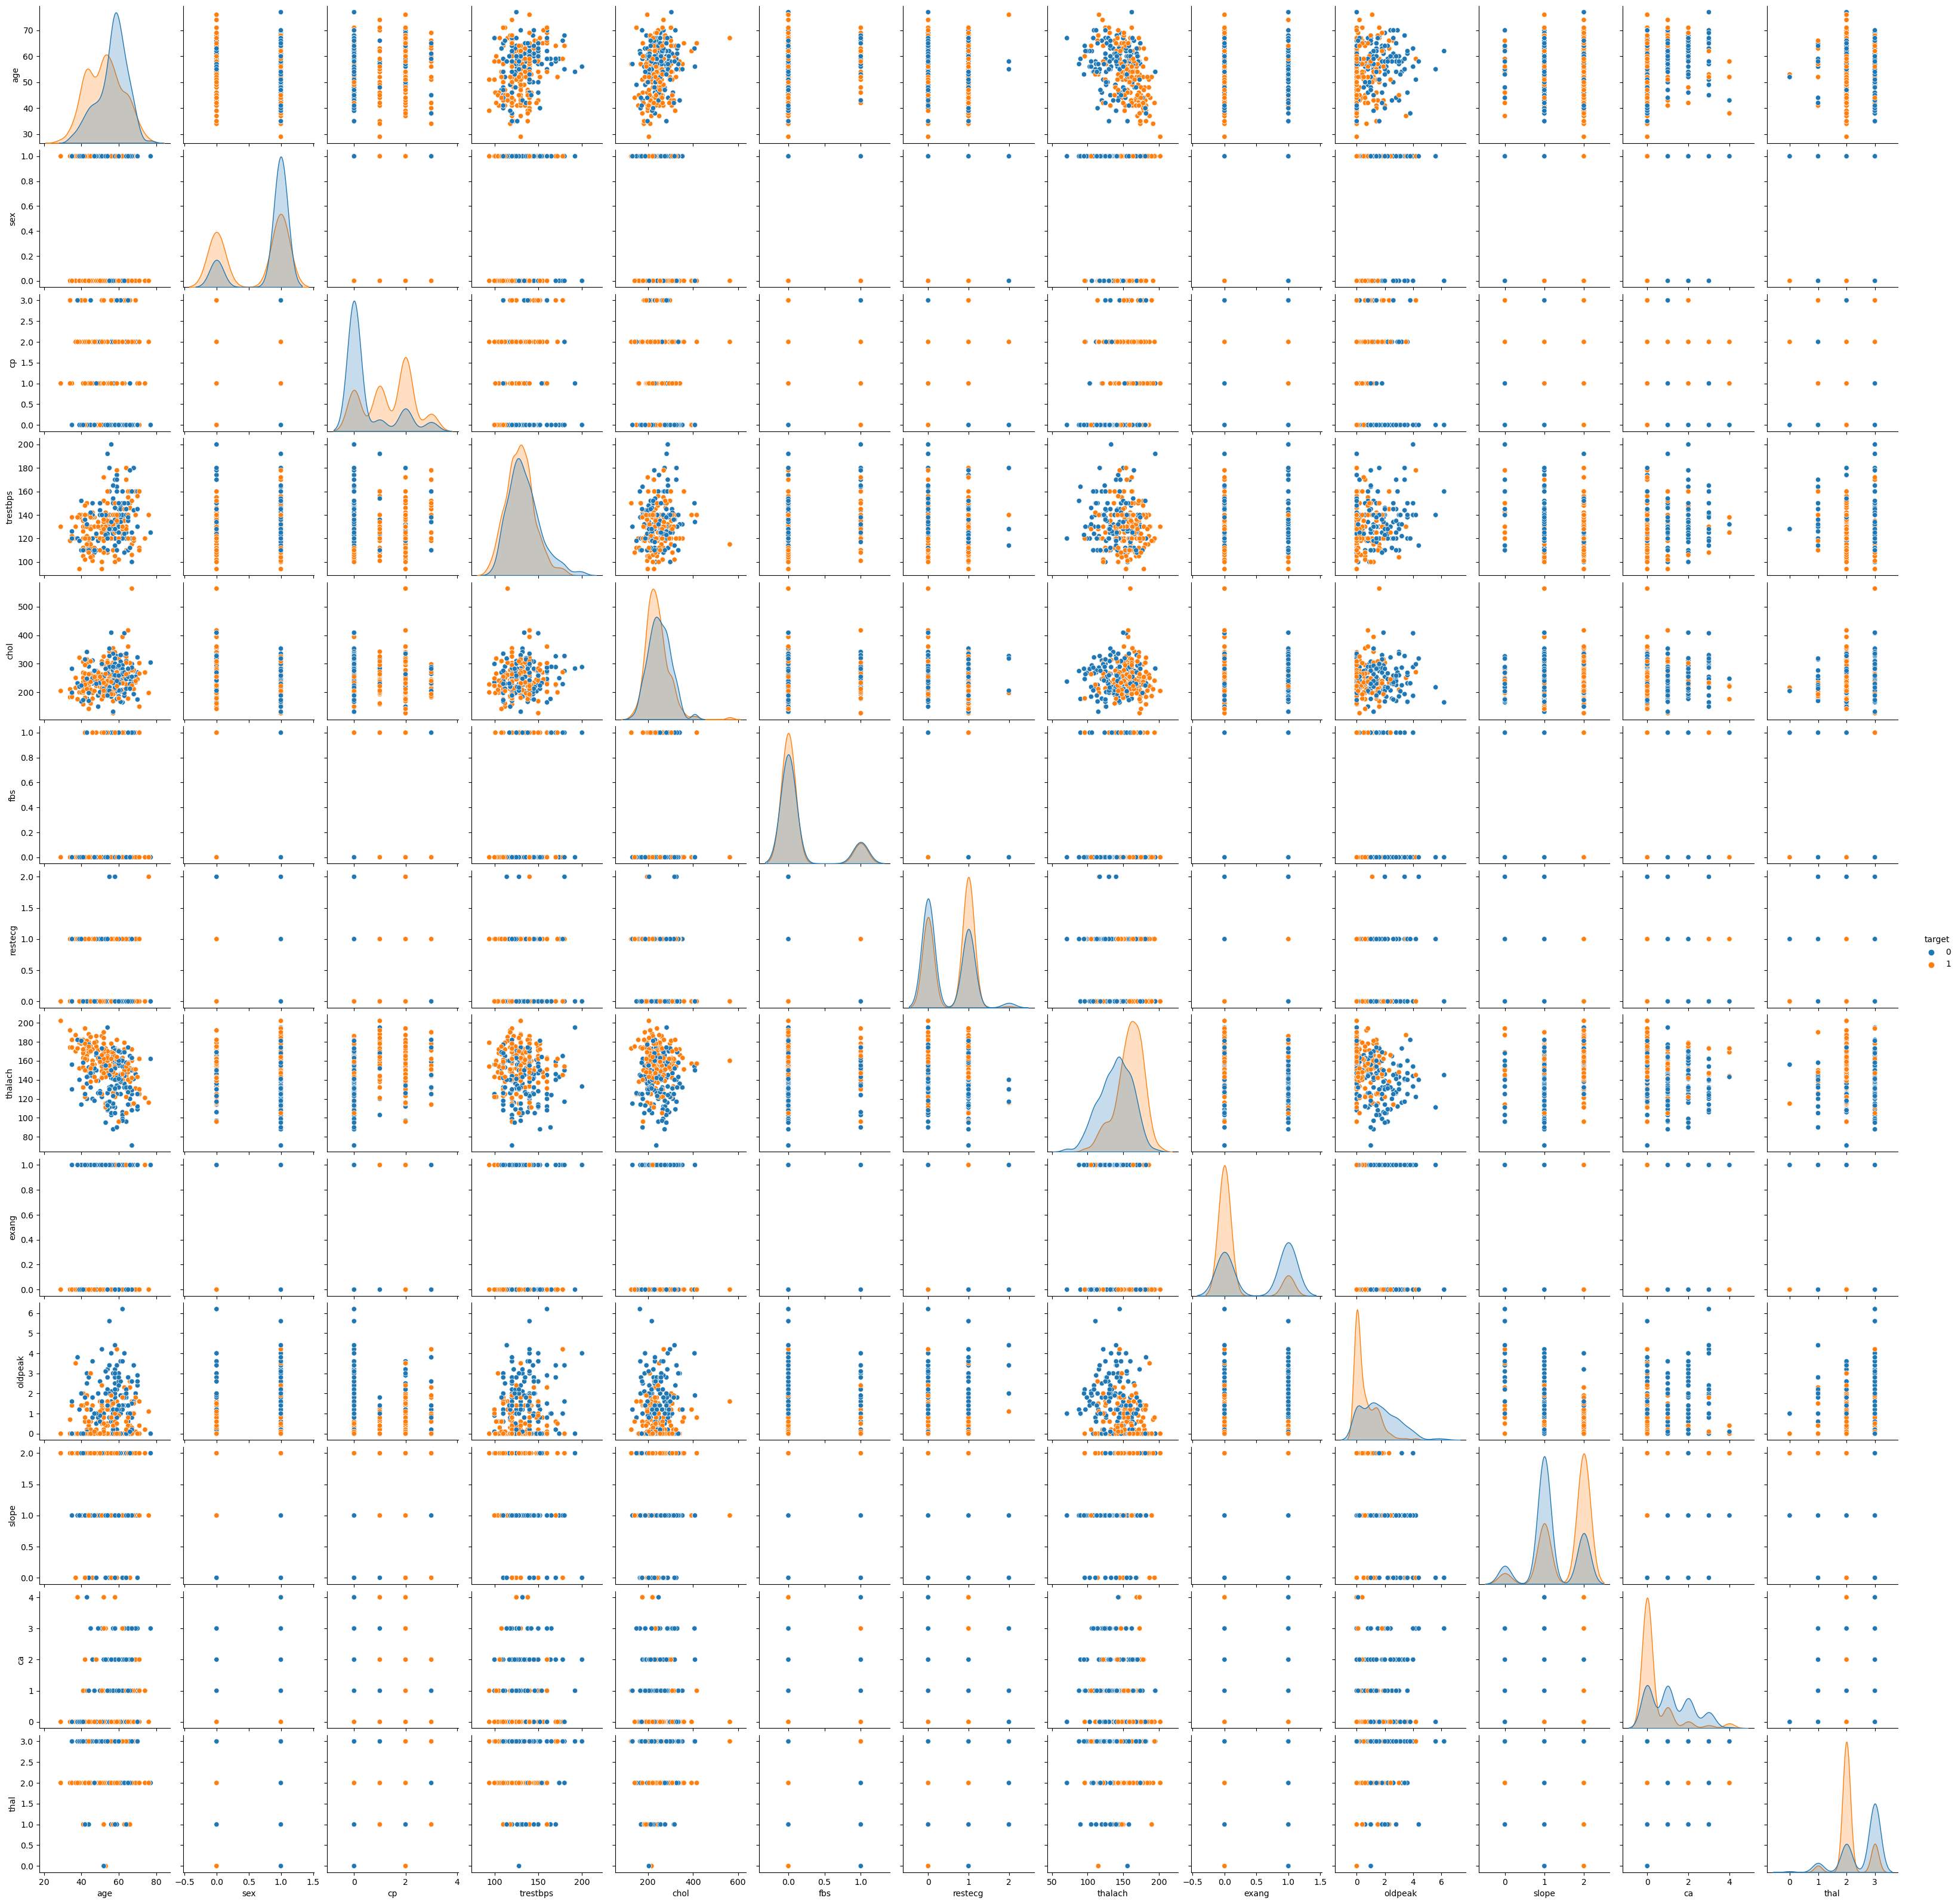

In [13]:
p=sns.pairplot(df, hue = 'target')

In [14]:
# Splitting the dataset into training and testing sets.
x = df.iloc[:, :-2]
y = df.iloc[:, -1]
x_train, x_test, y_train, y_test = train_test_split(x, y, random_state = 0, test_size = 0.35)

In [15]:
print("Shape of X before Dimensionality Reduction: ", x_train.shape)

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
lda = LDA()  # Linear Discriminant Analysis
x_train = lda.fit_transform(x_train, y_train)
x_test = lda.transform(x_test)

print("Shape of X after Dimensionality Reduction: ", x_train.shape)

Shape of X before Dimensionality Reduction:  (666, 12)
Shape of X after Dimensionality Reduction:  (666, 1)


In [16]:
# Standardize features
scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [17]:
# Train individual models
svm_model = svm.SVC(kernel='rbf')
svm_model.fit(x_train, y_train)

knn_model = neighbors.KNeighborsClassifier(n_neighbors=9, p = 2, metric = 'euclidean')
knn_model.fit(x_train, y_train)

rf_model = RandomForestClassifier(n_estimators=5,random_state=6, max_depth=5)
rf_model.fit(x_train, y_train)

RandomForestClassifier(max_depth=5, n_estimators=5, random_state=6)

In [18]:
# Make predictions on the test set
svm_pred = svm_model.predict(x_test)
knn_pred = knn_model.predict(x_test)
rf_pred = rf_model.predict(x_test)

In [19]:
# Evaluate individual models
svm_accuracy = accuracy_score(y_test, svm_pred)
knn_accuracy = accuracy_score(y_test, knn_pred)
rf_accuracy = accuracy_score(y_test, rf_pred)

print("SVM Accuracy:", svm_accuracy)
print("KNN Accuracy:", knn_accuracy)
print("Random Forest Accuracy:", rf_accuracy)

SVM Accuracy: 0.8746518105849582
KNN Accuracy: 0.8495821727019499
Random Forest Accuracy: 0.8802228412256268


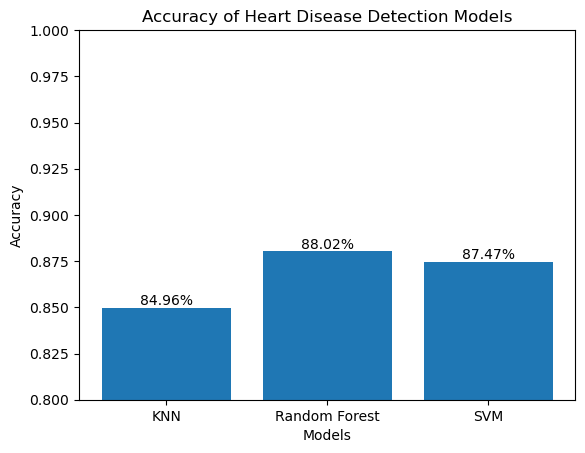

In [20]:
import matplotlib.pyplot as plt

# Accuracies of individual models
accuracies = [knn_accuracy, rf_accuracy, svm_accuracy]

# Model names
models = ['KNN', 'Random Forest', 'SVM']

# Plotting the bar plot
plt.bar(models, accuracies)
plt.xlabel('Models')
plt.ylabel('Accuracy')
plt.title('Accuracy of Heart Disease Detection Models')
plt.ylim(0.8, 1)  # Adjust the y-axis limits if needed

# Add value annotations on top of each bar
for i, v in enumerate(accuracies):
    plt.text(i, v, f'{v*100:.2f}%', ha='center', va='bottom')

plt.show()


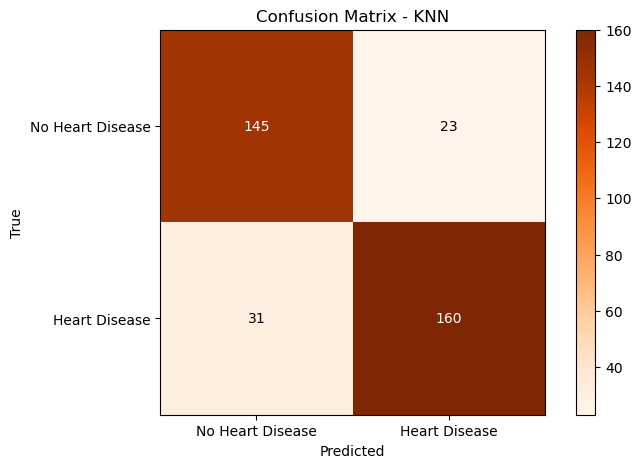

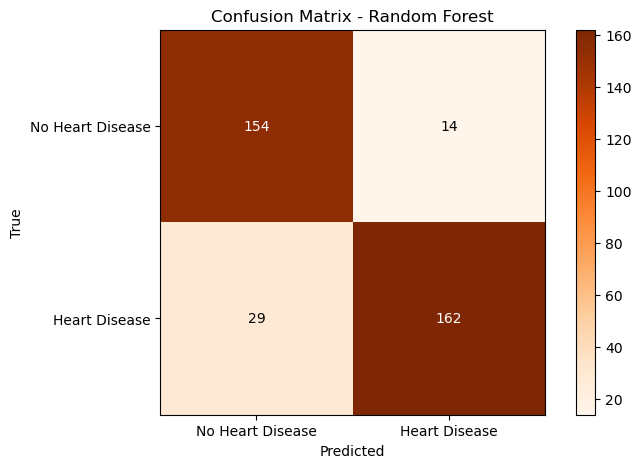

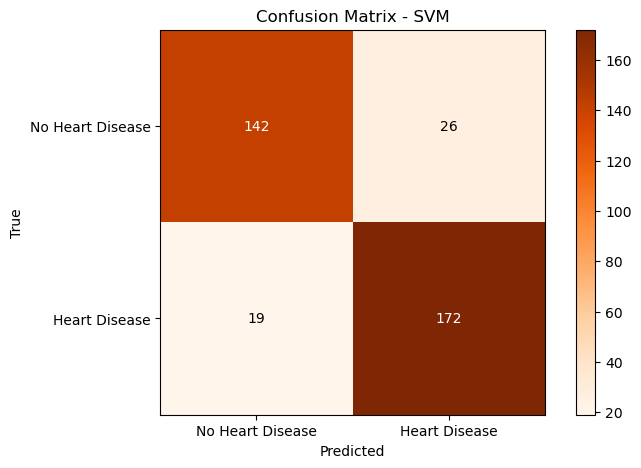

In [22]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import numpy as np

# Calculate the confusion matrix for each model
knn_cm = confusion_matrix(y_test, knn_pred)
rf_cm = confusion_matrix(y_test, rf_pred)
svm_cm = confusion_matrix(y_test, svm_pred)

# Function to print the confusion matrix
def print_confusion_matrix(cm, model_name):
    plt.figure(figsize=(8, 5))
    plt.imshow(cm, interpolation='nearest', cmap="Oranges")  # Use the "Oranges" colormap for orange color
    plt.title(f'Confusion Matrix - {model_name}')
    plt.colorbar()
    tick_marks = np.arange(2)
    plt.xticks(tick_marks, ['No Heart Disease', 'Heart Disease'])
    plt.yticks(tick_marks, ['No Heart Disease', 'Heart Disease'])
    plt.xlabel('Predicted')
    plt.ylabel('True')
    for i in range(2):
        for j in range(2):
            plt.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max() / 2 else 'black')
    plt.show()

# Print the confusion matrices
print_confusion_matrix(knn_cm, 'KNN')
print_confusion_matrix(rf_cm, 'Random Forest')
print_confusion_matrix(svm_cm, 'SVM')


# **PERFORMING K FOLD CROSS VALIDATION TO CHECK OVERFITTING**

In [23]:
from sklearn.ensemble import GradientBoostingClassifier  # Import the GradientBoostingClassifier
from sklearn.model_selection import KFold
from sklearn.metrics import accuracy_score, roc_auc_score, precision_score

# Define the KFold cross-validation object
kf = KFold(n_splits=5, shuffle=True, random_state=42)

# Define the machine learning model (in this example, GradientBoostingClassifier)
boosted_model = GradientBoostingClassifier()

# Initialize empty lists to store the accuracies, AUCs, and precisions
accuracies = []
aucs = []
precisions = []

# Perform k-fold cross-validation
for train_index, test_index in kf.split(x):  # Replace 'x' with your feature matrix
    X_train, X_test = x.iloc[train_index], x.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

    # Fit the model to the training data
    boosted_model.fit(X_train, y_train)

    # Predict the target variable for the test data
    y_pred = boosted_model.predict(X_test)

    # Predict the target variable probabilities for the test data
    y_proba = boosted_model.predict_proba(X_test)[:, 1]

    # Compute the accuracy score and store it in the list
    accuracy = accuracy_score(y_test, y_pred)
    accuracies.append(accuracy)

    # Compute precision score and store it into the list
    precision = precision_score(y_test, y_pred)
    precisions.append(precision)

    # Compute the AUC score and store it in the list
    auc = roc_auc_score(y_test, y_proba)
    aucs.append(auc)

    # Print the accuracy, precision, and AUC scores for the current fold
    print('Accuracy: %.3f, Precision: %.3f, AUC: %.3f' % (accuracy, precision, auc))

# Compute the mean accuracy, precision, and AUC across all folds
mean_accuracy = sum(accuracies) / len(accuracies)
mean_precision = sum(precisions) / len(precisions)
mean_auc = sum(aucs) / len(aucs)
print('Mean accuracy: %.3f, Mean precision: %.3f, Mean AUC: %.3f' % (mean_accuracy, mean_precision, mean_auc))


Accuracy: 0.961, Precision: 0.990, AUC: 0.983
Accuracy: 0.990, Precision: 1.000, AUC: 0.996
Accuracy: 0.976, Precision: 0.974, AUC: 0.998
Accuracy: 0.995, Precision: 1.000, AUC: 0.999
Accuracy: 0.922, Precision: 0.941, AUC: 0.987
Mean accuracy: 0.969, Mean precision: 0.981, Mean AUC: 0.993


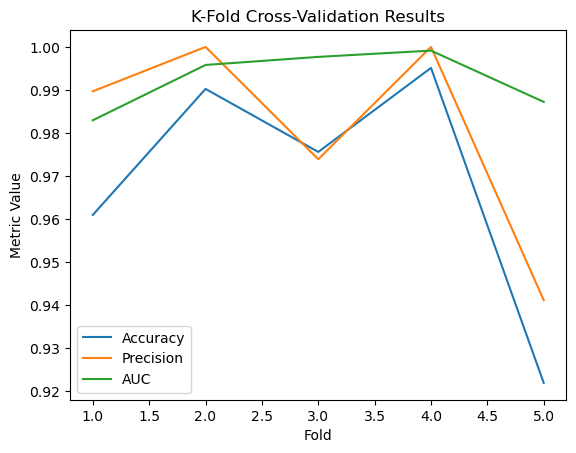

In [24]:
# Create an array representing the fold numbers
fold_numbers = np.arange(1, len(accuracies) + 1)

# Plot the accuracies
plt.plot(fold_numbers, accuracies, label='Accuracy')

# Plot the precisions
plt.plot(fold_numbers, precisions, label='Precision')

# Plot the AUCs
plt.plot(fold_numbers, aucs, label='AUC')

# Set the labels and title
plt.xlabel('Fold')
plt.ylabel('Metric Value')
plt.title('K-Fold Cross-Validation Results')

# Display the legend
plt.legend()

# Show the plot
plt.show()

# ** MANUAL TESTING DATA OBTAINED FROM AN ACTUAL PATIENT **

In [25]:
'''Manual testing of an actual heart disease patient's reports'''
# answer must be 1 (Disease risk detected)
import numpy as np
myData = np.array([[23, 0, 1, 127, 232, 0, 1, 168, 0, 1, 2, 2]])  # Reshape to a 2D array

# Predict using the trained model
prediction = boosted_model.predict(myData)

if prediction[0]:
    print("Caution! Heart Disease Risk is high, kindly book a checkup with your doctor.")
else:
    print("Congratulations! Your heart seems to be in perfect condition.")

Caution! Heart Disease Risk is high, kindly book a checkup with your doctor.


In [26]:
''' Manual testing for a healthy adult '''

secondData = np.array([[53, 0, 0, 146, 298, 1, 0, 168, 0, 1.8, 2, 3]])
ans = boosted_model.predict(secondData)
if not ans:
    print("Congratulations! Your heart seems to be in perfect condition.")
else:
    print("Caution! Heart Disease Risk is high, kindly book a checkup with your doctor.")

Congratulations! Your heart seems to be in perfect condition.


In [27]:
''' Manual testing for a healthy adult '''

secondData = np.array([[53, 0, 1, 136, 304, 1, 1, 172, 0, 0, 2, 0]])

                        
ans = boosted_model.predict(secondData)
if not ans:
    print("Congratulations! Your heart seems to be in perfect condition.")
else:
    print("Caution! Heart Disease Risk is high, kindly book a checkup with your doctor.")

Caution! Heart Disease Risk is high, kindly book a checkup with your doctor.
